In [10]:
from langgraph.graph import END, StateGraph
from typing_extensions import Annotated, TypedDict
import operator

In [11]:
# define shared state
# we use add_messages so both workers can append to the shared chat history

class State(TypedDict):
    messages: Annotated[list, operator.add]
    next_worker: str # decided by the supervisor

In [12]:
# 2. define worker nodes

def research_node(state: State):
    #simulating a research task
    return {
        "messages":[
            "Research Agent: Found recent documentation and data sources."
        ]
    }


def code_node(state: State):
    #simulating a coding task
    return {
        "messages":["Code Agent: wrote and tested the requested python script."]
    }

In [13]:
# 3. def the central supervisor node

def supervisor_node(State: State):
    # in a prod system, an llm looks at the messages and decides
    # whether to route to 'research' , 'code' , or 'end' 
    last_message = State["messages"][-1].lower()

     # FIX: Check if a worker already completed the request to avoid infinite looping
    if last_message.startswith("code agent:") or last_message.startswith(
        "research agent:"
    ):
        return {"next_worker": "FINISH"}


    if "code" in last_message or "python" in last_message:
        return {"next_worker": "code_worker"}
    elif "research" in last_message or "find" in last_message:
        return {"next_worker":"research_worker"}
    else:
        return {"next_worker":"FINISH"}


In [14]:
#4. Router function for conditional edges

def route_from_supervisor(state: State):
    return state.get("next_worker","FINISH")

In [15]:
# 5. Build Graph
workflow = StateGraph(State)

# Add nodes
workflow.add_node("supervisor", supervisor_node)
workflow.add_node("research_worker", research_node)
workflow.add_node("code_worker", code_node)

# Set entry point to supervisor
workflow.set_entry_point("supervisor")

# Add conditional edges from supervisor to workers or END
workflow.add_conditional_edges(
    "supervisor",
    route_from_supervisor,
    {
        "research_worker": "research_worker",
        "code_worker": "code_worker",
        "FINISH": END,
    },
)

# Once workers finish, loop back to supervisor so it can review or conclude
workflow.add_edge("research_worker", "supervisor")
workflow.add_edge("code_worker", "supervisor")

app = workflow.compile()

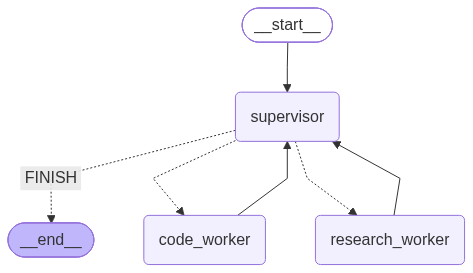

In [16]:
app

In [17]:
# --- Run the Hierarchical App ---
config = {"configurable": {"thread_id": "hierarchical_test_1"}}

print("Invoking graph with a coding task...")
result = app.invoke(
    {"messages": ["Please write some python code for our project."]},
    config=config,
)

print("\nFinal State Output:")
for msg in result["messages"]:
  print(f" - {msg}")

Invoking graph with a coding task...

Final State Output:
 - Please write some python code for our project.
 - Code Agent: wrote and tested the requested python script.


In [19]:
# --- Run the Hierarchical App ---
config = {"configurable": {"thread_id": "hierarchical_test_2"}}

print("Invoking graph with a research task...")
result = app.invoke(
    {"messages": ["Please research on RAG for our project."]},
    config=config,
)

print("\nFinal State Output:")
for msg in result["messages"]:
  print(f" - {msg}")

Invoking graph with a research task...

Final State Output:
 - Please research on RAG for our project.
 - Research Agent: Found recent documentation and data sources.


In [20]:
config = {"configurable": {"thread_id": "hierarchical_test_2"}}

for event in app.stream({"messages": ["Please research on RAG for our project."]},config = config ,stream_mode="values"):
  print(event)
  print("-" * 40)

{'messages': ['Please research on RAG for our project.']}
----------------------------------------
{'messages': ['Please research on RAG for our project.'], 'next_worker': 'research_worker'}
----------------------------------------
{'messages': ['Please research on RAG for our project.', 'Research Agent: Found recent documentation and data sources.'], 'next_worker': 'research_worker'}
----------------------------------------
{'messages': ['Please research on RAG for our project.', 'Research Agent: Found recent documentation and data sources.'], 'next_worker': 'FINISH'}
----------------------------------------


In [21]:
config = {"configurable": {"thread_id": "hierarchical_test_2"}}

for event in app.stream({"messages": ["Please research on RAG for our project."]},config = config ,stream_mode="updates"):
  print(event)
  print("-" * 40)

{'supervisor': {'next_worker': 'research_worker'}}
----------------------------------------
{'research_worker': {'messages': ['Research Agent: Found recent documentation and data sources.']}}
----------------------------------------
{'supervisor': {'next_worker': 'FINISH'}}
----------------------------------------
